# 02 - Nettoyage des données

**Projet :** EnergyForecast, prévision de la production solaire photovoltaïque.

Ce notebook applique les corrections identifiées dans `01_exploration.ipynb`.

**Principes suivis :**
- On ne supprime **aucune ligne** : en séries temporelles, il faut garder une grille régulière (1 ligne = 5 minutes), sinon les retards (lags) deviennent faux.
- Une valeur invalide devient `NaN` (valeur manquante), on ne la "corrige" pas au hasard.
- On n'invente que les **trous courts** (interpolation sur 1 h maximum). Les longues pannes restent vides et sont signalées.
- La puissance (variable à prédire) n'est **jamais** interpolée.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "../data/raw/PV_firstRealease.xlsx"
OUT_PATH = "../data/processed/pv_clean.csv"


## 1. Chargement et mise en forme

On assemble les 3 feuilles dans un seul tableau avec une colonne `year`, on renomme les colonnes
(noms courts, en minuscules, avec l'unité) et on reconstruit la position dans le temps.

Le fichier n'a pas de vraie date : on utilise `year`, `step` (numéro de la ligne dans l'année, 0 à 105119)
et `day_of_year` (1 à 365).

In [3]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None)

frames = []
for i, (name, d) in enumerate(sheets.items(), start=1):
    d = d.copy()
    d.insert(0, "year", i)
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)

# Colonnes de minutes : la fin est redondante avec le début, on garde seulement le début
raw = raw.rename(columns=lambda c: "minute" if c.startswith("Starting minute") else c)
raw = raw.drop(columns=[c for c in raw.columns if c.startswith("Ending minute")])

RENAME = {
    "Hour": "hour",
    "Generated power": "power_kw",
    "TemperatureC": "temp_c",
    "DewpointC": "dewpoint_c",
    "PressurehPa": "pressure_hpa",
    "WindDirectionDegrees": "wind_dir_deg",
    "WindSpeedKMH": "wind_speed_kmh",
    "WindSpeedGustKMH": "wind_gust_kmh",
    "Humidity": "humidity_pct",
    "HourlyPrecipMM": "precip_hourly_mm",
    "dailyrainMM": "rain_daily_mm",
    "SolarRadiationWatts_m2": "solar_rad_wm2",
}
raw = raw.rename(columns=RENAME)

raw["step"] = raw.groupby("year").cumcount()
raw["day_of_year"] = raw["step"] // 288 + 1

# Vérification : les colonnes hour/minute suivent bien la grille de 5 minutes
assert (raw["hour"] == (raw["step"] // 12) % 24).all()
assert (raw["minute"] == (raw["step"] % 12) * 5).all()

STATION = ["temp_c", "dewpoint_c", "pressure_hpa", "wind_dir_deg", "wind_speed_kmh",
           "wind_gust_kmh", "humidity_pct", "precip_hourly_mm", "rain_daily_mm", "solar_rad_wm2"]
MEASURES = ["power_kw"] + STATION

raw = raw[["year", "step", "day_of_year", "hour", "minute"] + MEASURES]
print(raw.shape)
raw.head()

(315360, 16)


,year,step,day_of_year,hour,minute,power_kw,temp_c,dewpoint_c,pressure_hpa,wind_dir_deg,wind_speed_kmh,wind_gust_kmh,humidity_pct,precip_hourly_mm,rain_daily_mm,solar_rad_wm2
0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1,1,1,0,5,0,0,0,0,0,0,0,0,0,0,0
2,1,2,1,0,10,0,11,8,1021,114,1,17,83,0,0,0
3,1,3,1,0,15,0,11,8,1021,134,12,17,83,0,0,0
4,1,4,1,0,20,0,11,8,1021,128,8,17,83,0,0,0


## 2. Journal des modifications

Pour suivre l'impact de chaque étape, on compte combien de valeurs deviennent `NaN` à chaque fois.

In [4]:
df = raw.copy()
log = []

def n_missing():
    return int(df[MEASURES].isna().sum().sum())

def add_log(label, before):
    log.append({"étape": label, "valeurs masquées (NaN)": n_missing() - before})


## 3. Codes d'erreur capteur

`-999` et `65535` sont des codes d'erreur (valeurs impossibles qui reviennent toujours à l'identique).
On les remplace par `NaN`.

In [5]:
before = n_missing()
for sentinel in (-999, 65535):
    df[MEASURES] = df[MEASURES].mask(df[MEASURES] == sentinel)
add_log("Codes d'erreur (-999, 65535)", before)

## 4. Zéros fantômes (station météo en panne)

Une température, une pression et une humidité à 0 **en même temps** signalent une panne de la station.
On met à `NaN` toutes les mesures de la station sur ces lignes.

La puissance n'est pas touchée : elle vient de l'installation photovoltaïque, pas de la station.

In [6]:
before = n_missing()
ghost = (df[["temp_c", "pressure_hpa", "humidity_pct"]] == 0).all(axis=1)
print("Lignes de panne station :", int(ghost.sum()), f"({100 * ghost.mean():.1f} %)")
df.loc[ghost, STATION] = np.nan
add_log("Zéros fantômes (station en panne)", before)

Lignes de panne station : 28256 (9.0 %)


## 5. Lignes en unités américaines (année 3)

En explorant l'année 3, on trouve 24 jours (jours 248 à 337) où la température et le point de rosée
sont en **degrés Fahrenheit** et la pression en **pouces de mercure** (valeurs autour de 29 à 30 au lieu de 1000 hPa).

C'est un piège : une température de 45 °F ressemble à 45 °C et passerait les seuils sans alerte.
On repère ces lignes grâce à la pression (entre 20 et 35), puis :
- température et point de rosée : conversion en degrés Celsius,
- pression : mise à `NaN` (une valeur entière en pouces donne une précision d'environ 17 hPa, inutilisable),
- vent et pluie : unités incertaines, on les garde telles quelles mais on signale les lignes dans `units_converted`.

In [7]:
imperial = df["pressure_hpa"].between(20, 35)
print("Lignes en unités américaines :", int(imperial.sum()),
      "| années concernées :", sorted(df.loc[imperial, "year"].unique()),
      "| jours :", df.loc[imperial, "day_of_year"].nunique())

for col in ["temp_c", "dewpoint_c"]:
    df.loc[imperial, col] = ((df.loc[imperial, col] - 32) * 5 / 9).round(1)

before = n_missing()
df.loc[imperial, "pressure_hpa"] = np.nan
add_log("Pression en pouces de mercure (inutilisable)", before)
df["units_converted"] = imperial

Lignes en unités américaines : 5416 | années concernées : [np.int64(3)] | jours : 24


## 6. Valeurs hors plage physique

On rejette ce qui est physiquement impossible. Attention : les températures négatives (jusqu'à -30 °C)
sont légitimes en hiver, on garde donc une borne basse réaliste plutôt que 0.

In [8]:
BOUNDS = {
    "power_kw": (0, 7000),
    "temp_c": (-30, 50),
    "dewpoint_c": (-30, 35),
    "pressure_hpa": (900, 1080),
    "wind_dir_deg": (0, 360),
    "wind_speed_kmh": (0, 150),
    "wind_gust_kmh": (0, 200),
    "humidity_pct": (1, 100),       # 0 % d'humidité en extérieur n'est pas réaliste
    "precip_hourly_mm": (0, 100),
    "rain_daily_mm": (0, 300),
    "solar_rad_wm2": (0, 1400),
}

before = n_missing()
per_col = {}
for col, (lo, hi) in BOUNDS.items():
    bad = (df[col] < lo) | (df[col] > hi)
    per_col[col] = int(bad.sum())
    df.loc[bad, col] = np.nan
add_log("Valeurs hors plage physique", before)
pd.Series(per_col, name="valeurs rejetées").to_frame()

,valeurs rejetées
power_kw,5
temp_c,2
dewpoint_c,2
pressure_hpa,77
wind_dir_deg,0
wind_speed_kmh,2
wind_gust_kmh,887
humidity_pct,195
precip_hourly_mm,103
rain_daily_mm,60


## 7. Cohérence : point de rosée et température

Le point de rosée ne peut pas dépasser la température de l'air. On laisse 1 °C de tolérance
(les valeurs sont arrondies à l'entier).

In [9]:
before = n_missing()
bad_dew = df["dewpoint_c"] > df["temp_c"] + 1
print("Points de rosée incohérents :", int(bad_dew.sum()))
df.loc[bad_dew, "dewpoint_c"] = np.nan
add_log("Point de rosée > température", before)

Points de rosée incohérents : 51


## 8. Puissance figée (capteur bloqué)

En explorant, on voit de la puissance positive **la nuit** en années 1 et 2, avec exactement la même valeur
répétée pendant des heures (par exemple 1037 répété plus de 1 300 fois). C'est un capteur qui garde sa dernière
valeur en mémoire.

Règle : une même valeur positive répétée **12 fois de suite ou plus** (1 heure) est considérée comme figée.
On exclut la valeur maximale (6057), qui est un plafond atteint légitimement en plein soleil.

In [10]:
before = n_missing()
p = df["power_kw"]
cap = p.max()
print("Plafond de puissance observé :", cap)

run_id = (p != p.shift()).cumsum()
run_len = p.groupby(run_id).transform("size")
stuck = (run_len >= 12) & (p > 0) & (p < cap)

nb_runs = run_id[stuck].nunique()
print("Séquences figées :", nb_runs, "| lignes concernées :", int(stuck.sum()))
print(df.loc[stuck].groupby("year").size().rename("lignes figées par année"))

df.loc[stuck, "power_kw"] = np.nan
add_log("Puissance figée (capteur bloqué)", before)

Plafond de puissance observé : 6057.0
Séquences figées : 32 | lignes concernées : 14490
year
1    11041
2     3432
3       17
Name: lignes figées par année, dtype: int64


## 9. Bilan des valeurs masquées

In [11]:
pd.DataFrame(log)

,étape,valeurs masquées (NaN)
0,"Codes d'erreur (-999, 65535)",189
1,Zéros fantômes (station en panne),282560
2,Pression en pouces de mercure (inutilisable),5416
3,Valeurs hors plage physique,1373
4,Point de rosée > température,51
5,Puissance figée (capteur bloqué),14490


## 10. Interpolation des trous courts

On comble uniquement les trous **de 1 heure maximum** (12 lignes), année par année, selon le type de variable :

| Type | Variables | Méthode |
|---|---|---|
| Variables lisses | température, rosée, pression, humidité, vent, rafales | interpolation linéaire (trou <= 1 h) |
| Radiation solaire | `solar_rad_wm2` | interpolation linéaire (trou <= 15 min, elle varie vite) |
| Variables "en escalier" | direction du vent, pluie | dernière valeur connue (trou <= 1 h) |

Un trou plus long reste entièrement `NaN`. La puissance n'est jamais comblée.

In [12]:
def fill_short_gaps(s, max_gap, method):
    """Comble uniquement les trous de longueur <= max_gap (pas de remplissage partiel)."""
    is_na = s.isna()
    run_id = (is_na != is_na.shift()).cumsum()
    run_len = is_na.groupby(run_id).transform("size")
    short = is_na & (run_len <= max_gap)
    filled = s.interpolate(method="linear", limit_area="inside") if method == "linear" else s.ffill()
    return s.where(~short, filled)

SMOOTH = ["temp_c", "dewpoint_c", "pressure_hpa", "humidity_pct", "wind_speed_kmh", "wind_gust_kmh"]
STEPWISE = ["wind_dir_deg", "precip_hourly_mm", "rain_daily_mm"]

na_before = df[STATION].isna()

parts = []
for year, g in df.groupby("year"):
    g = g.copy()
    for col in SMOOTH:
        g[col] = fill_short_gaps(g[col], 12, "linear")
    g["solar_rad_wm2"] = fill_short_gaps(g["solar_rad_wm2"], 3, "linear")
    for col in STEPWISE:
        g[col] = fill_short_gaps(g[col], 12, "ffill")
    parts.append(g)
df = pd.concat(parts).sort_index()

na_after = df[STATION].isna()
df["meteo_imputed"] = (na_before & ~na_after).any(axis=1)
print("Lignes avec au moins une valeur interpolée :", int(df["meteo_imputed"].sum()))

Lignes avec au moins une valeur interpolée : 8773


## 11. Lignes exploitables

On ajoute une colonne `usable` : elle vaut `True` quand la puissance **et** toutes les variables météo
sont présentes. Les lignes `False` ne sont pas supprimées, on les écartera au moment de la modélisation.

In [13]:
df["usable"] = df[MEASURES].notna().all(axis=1)

summary = df.groupby("year").agg(lignes=("usable", "size"),
                                 exploitables=("usable", "sum"))
summary["% exploitable"] = (100 * summary["exploitables"] / summary["lignes"]).round(1)
summary

,lignes,exploitables,% exploitable
year,,,
1,105120,90927,86.5
2,105120,96875,92.2
3,105120,86693,82.5


In [14]:
missing_after = (df.groupby("year")[MEASURES].apply(lambda g: g.isna().mean() * 100)).round(2).T
missing_after.columns = [f"Year {c}" for c in missing_after.columns]
missing_after.rename_axis("% de NaN après nettoyage")

,Year 1,Year 2,Year 3
% de NaN après nettoyage,,,
power_kw,10.51,3.26,0.02
temp_c,3.08,4.51,11.02
dewpoint_c,3.14,4.51,11.02
pressure_hpa,3.11,4.51,16.22
wind_dir_deg,3.08,4.51,11.02
wind_speed_kmh,3.08,4.51,11.02
wind_gust_kmh,3.11,4.51,11.85
humidity_pct,3.11,4.51,11.22
precip_hourly_mm,3.11,4.51,11.05


## 12. Vérifications finales

In [15]:
print("Valeurs sentinelles restantes :", int(df[MEASURES].isin([-999, 65535]).sum().sum()))

ok = True
for col, (lo, hi) in BOUNDS.items():
    s = df[col].dropna()
    if ((s < lo) | (s > hi)).any():
        ok = False
        print("Hors plage :", col)
print("Toutes les valeurs dans les plages physiques :", ok)

# Puissance positive la nuit (22h-3h) : ne devrait plus exister
night = df["hour"].isin([22, 23, 0, 1, 2, 3])
print("Puissance > 0 entre 22h et 3h :", int(((df["power_kw"] > 0) & night).sum()))

# Information : puissance nulle en plein jour alors que la radiation est forte
day_zero = (df["power_kw"] == 0) & (df["solar_rad_wm2"] > 300)
print("Puissance = 0 alors que radiation > 300 W/m2 :", int(day_zero.sum()))

df[MEASURES].describe().T[["min", "max", "mean"]].round(1)

Valeurs sentinelles restantes : 0
Toutes les valeurs dans les plages physiques : True
Puissance > 0 entre 22h et 3h : 0
Puissance = 0 alors que radiation > 300 W/m2 : 6827


,min,max,mean
power_kw,0.0,6057.0,735.3
temp_c,-17.0,39.0,15.3
dewpoint_c,-17.0,23.0,11.0
pressure_hpa,976.0,1038.0,1017.4
wind_dir_deg,0.0,360.0,219.6
wind_speed_kmh,0.0,69.0,3.7
wind_gust_kmh,0.0,103.0,9.8
humidity_pct,10.0,100.0,77.6
precip_hourly_mm,0.0,99.0,0.1
rain_daily_mm,0.0,194.0,1.8


## 13. Avant / après : la pression en année 3

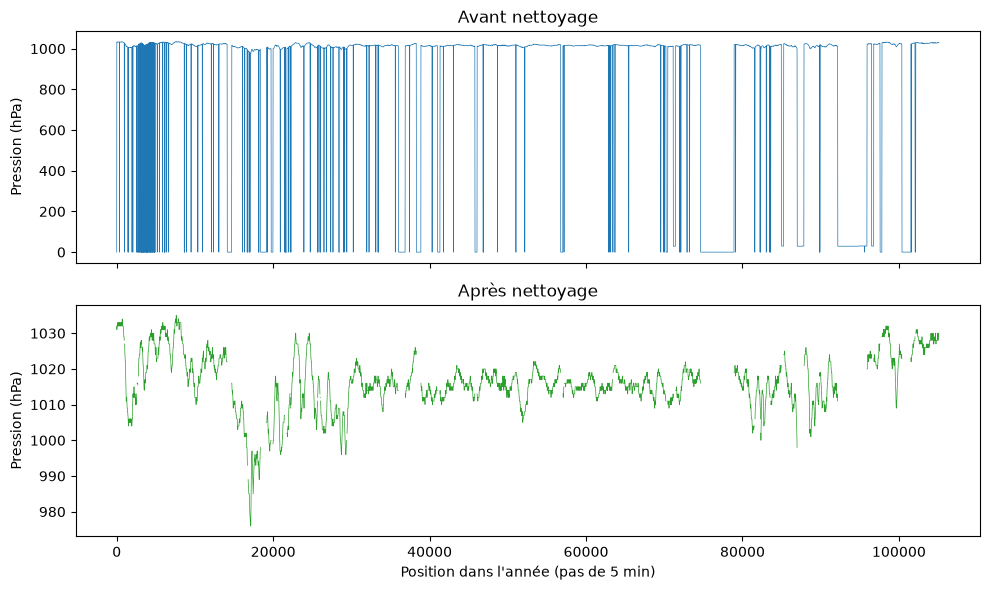

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
y3_raw = raw[raw["year"] == 3].iloc[::12]
y3_cln = df[df["year"] == 3].iloc[::12]

axes[0].plot(y3_raw["step"], y3_raw["pressure_hpa"], lw=0.5)
axes[0].set_title("Avant nettoyage")
axes[0].set_ylabel("Pression (hPa)")

axes[1].plot(y3_cln["step"], y3_cln["pressure_hpa"], lw=0.5, color="tab:green")
axes[1].set_title("Après nettoyage")
axes[1].set_ylabel("Pression (hPa)")
axes[1].set_xlabel("Position dans l'année (pas de 5 min)")

plt.tight_layout()
plt.savefig("../reports/figures/avant_apres_pression.png", dpi=150)
plt.show()

## 14. Sauvegarde

In [17]:
df.to_csv(OUT_PATH, index=False)
print("Fichier sauvegardé :", OUT_PATH, df.shape)

Fichier sauvegardé : ../data/processed/pv_clean.csv (315360, 19)


## 15. Résumé des décisions

- Aucune ligne supprimée : la grille de 5 minutes est conservée (3 x 105 120 lignes).
- Codes d'erreur (-999, 65535), zéros fantômes de la station et valeurs hors plage physique remplacés par `NaN`.
- 24 jours de l'année 3 en unités américaines : température et rosée converties en °C, pression masquée.
- Puissance figée (même valeur répétée >= 1 h) détectée et mise à `NaN`.
- Trous météo de 1 h maximum interpolés, les longues pannes restent vides.
- La puissance (cible) n'est jamais interpolée.
- Trois colonnes de contrôle : `units_converted` (ligne en unités américaines), `meteo_imputed` (une valeur a été comblée) et `usable` (ligne complète).

**Limites à garder en tête**
- Pour les lignes en unités américaines, les unités du vent et de la pluie sont incertaines (non converties).
- Le fichier n'a pas de vraie date, on travaille avec `year`, `day_of_year`, `hour` et `minute`.
- Les périodes de puissance à 0 en plein jour (panne possible de l'onduleur) ne sont pas distinguables d'une vraie production nulle, elles sont seulement signalées dans les vérifications.

**Prochaine étape :** `03_features.ipynb` (variables temporelles, retards, découpage train / validation / test).